# An N-Gram Language Model for Ewe

Ewe (*Eʋegbe*) is a Gbe language spoken mainly in south-eastern Ghana and southern Togo. It is **low-resource**: there is little digitised text, so instead of a neural network we build a **word-level n-gram model**, which learns by counting which words follow which.

We build models that look back 0 to 4 words (orders 1 to 5), tune them on a development set, score them once on a held-out test set, and use them to generate text.

| Letter | Approximate sound |
|---|---|
| ɔ | open "o", as in *off* |
| ɛ | open "e", as in *bed* |
| ŋ | "ng", as in *sing* |
| ɖ | retroflex "d" |
| ƒ | bilabial "f" |

These letters change meaning (`ko` ≠ `kɔ`), so the text cleaning must keep them.

## Setup

In [1]:
import math
import random
import re
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11})

START = '<s>'
END = '</s>'
UNKNOWN = '<UNK>'
HIGHEST_ORDER = 5
ORDER_NAMES = {1: 'unigram', 2: 'bigram', 3: 'trigram', 4: '4-gram', 5: '5-gram'}
RANDOM_SEED = 42

## 1. Loading the data

We use the Ewe text from two sources:
- **`EWE_ENGLISH.csv`**: the Ewe side of *EWE-English Bilingual Pairs* (Tchaye-Kondi & Gbedevi, Kaggle, DOI 10.34740/KAGGLE/DSV/1462736), crawled from literary texts, religious texts, the Universal Declaration of Human Rights and general websites.
- **`waxal_transcriptions.xlsx`**: Ewe image-caption transcriptions (Waxal, University of Ghana, 2023).

In [2]:
kaggle_table = pd.read_csv('data/EWE_ENGLISH.csv', index_col=0)
kaggle_lines = kaggle_table['EWE'].dropna().astype(str).tolist()

print(f'Kaggle lines: {len(kaggle_lines):,}')
print('Example:', kaggle_lines[0])

Kaggle lines: 28,614
Example: Ne nyɔnu aɖe le evi dzim eye wo le kukum nɛ la, o wɔna kɔnu na ɖevi yeye si wo ga dzi la, to ŋkɔ bubu tsɔtsɔ nɛ la me, bena ɖevi yeyela me ga ku ke o.



In [3]:
waxal_table = pd.read_excel('data/waxal_transcriptions.xlsx', usecols=['Transcription'])
waxal_column = waxal_table['Transcription'].dropna().str.strip().str.strip('\xa0')
waxal_lines = waxal_column[waxal_column.str.len() > 0].tolist()

print(f'Waxal lines: {len(waxal_lines):,}')
print('Example:', waxal_lines[0])

Waxal lines: 19,151
Example: Eʋumidzraƒe le mɔ to. Ame aɖewo tɔ ɖe emɔ to. Nyɔnu eve kple ɖevi ame etɔ wole bagwo ɖe asi wonɔ motodola aɖe kpɔm le mɔ to.


Total lines: 47,765
count    47765.0
mean        27.2
std         18.4
min          1.0
25%         16.0
50%         26.0
75%         35.0
max        416.0


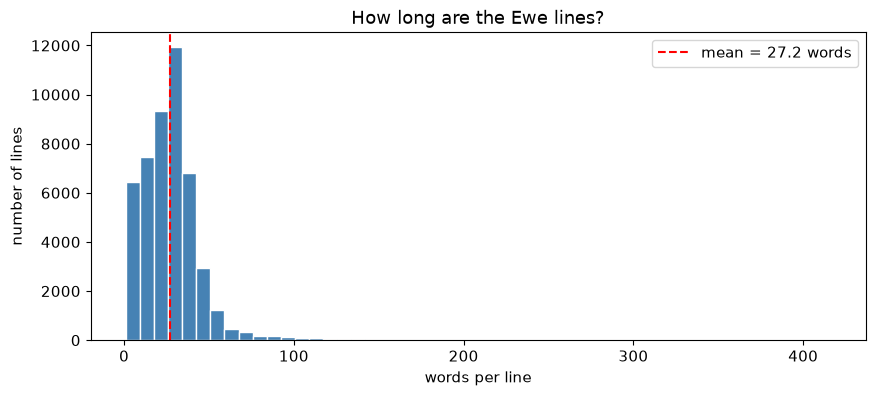

In [4]:
all_lines = kaggle_lines + waxal_lines
words_per_line = pd.Series([len(line.split()) for line in all_lines])

print(f'Total lines: {len(all_lines):,}')
print(words_per_line.describe().round(1).to_string())

plt.hist(words_per_line, bins=50, color='steelblue', edgecolor='white')
plt.axvline(words_per_line.mean(), color='red', linestyle='--', label=f'mean = {words_per_line.mean():.1f} words')
plt.xlabel('words per line')
plt.ylabel('number of lines')
plt.title('How long are the Ewe lines?')
plt.legend()
plt.show()

## 2. Cleaning the text

For every line we:
1. lowercase it, so `Ame` and `ame` count as the same word;
2. keep `. , ! ?` as their own tokens, because a model that never sees punctuation can never produce it, and they mark where sentences and clauses end;
3. drop every other symbol and all digits (verse numbers, quotes, brackets);
4. add `<s>` at the start and `</s>` at the end, so the model learns how sentences begin and finish.

Python's `\w` understands Unicode, so `ɔ ɛ ŋ ɖ ƒ` survive. One known limitation: accents stored as a separate character (such as the tilde in `ɔ̃`) are not `\w`, so they get split off.

In [5]:
def clean_and_tokenize(line):
    text = line.lower()
    text = re.sub(r'([.,!?])', r' \1 ', text)
    text = re.sub(r'[^\w\s.,!?]', ' ', text)
    text = re.sub(r'\d+', '', text)
    words = text.split()
    if not words:
        return []
    return [START] + words + [END]


print(clean_and_tokenize('Ne nyɔnu aɖe le evi dzim eye wo le kukum nɛ la,'))

['<s>', 'ne', 'nyɔnu', 'aɖe', 'le', 'evi', 'dzim', 'eye', 'wo', 'le', 'kukum', 'nɛ', 'la', ',', '</s>']


In [6]:
sentences = []
for line in all_lines:
    tokens = clean_and_tokenize(line)
    if tokens:
        sentences.append(tokens)

word_frequencies = Counter(token for sentence in sentences for token in sentence if token not in (START, END))
words_seen_once = sum(1 for count in word_frequencies.values() if count == 1)

print(f'Sentences:       {len(sentences):,}')
print(f'Tokens:          {sum(len(sentence) for sentence in sentences):,}')
print(f'Distinct words:  {len(word_frequencies):,}')
print(f'Words seen once: {words_seen_once:,} ({100 * words_seen_once / len(word_frequencies):.1f}%)')

Sentences:       47,131
Tokens:          1,527,719
Distinct words:  42,260
Words seen once: 21,794 (51.6%)


Half of all distinct words appear only once. That is what *low-resource* looks like in numbers, and it is why the model needs smoothing (section 5).

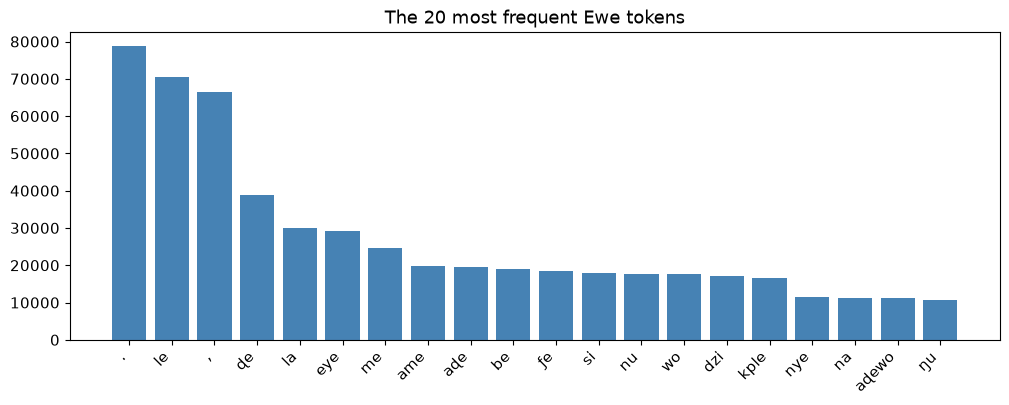

In [7]:
top_words, top_counts = zip(*word_frequencies.most_common(20))

plt.figure(figsize=(12, 4))
plt.bar(top_words, top_counts, color='steelblue')
plt.xticks(rotation=45, ha='right')
plt.title('The 20 most frequent Ewe tokens')
plt.show()

## 3. Splitting into train, dev and test

We shuffle the sentences with a fixed seed (so anyone re-running gets the same split) and cut them 80 / 10 / 10:
- **train**: the only text the model counts from;
- **dev**: used to choose the smoothing settings;
- **test**: scored exactly once, at the end, so the final number is honest.

In [8]:
random.seed(RANDOM_SEED)
shuffled_sentences = sentences.copy()
random.shuffle(shuffled_sentences)

train_end = int(0.8 * len(shuffled_sentences))
dev_end = int(0.9 * len(shuffled_sentences))

train_sentences = shuffled_sentences[:train_end]
dev_sentences = shuffled_sentences[train_end:dev_end]
test_sentences = shuffled_sentences[dev_end:]

print(f'train: {len(train_sentences):,}   dev: {len(dev_sentences):,}   test: {len(test_sentences):,}')

train: 37,704   dev: 4,713   test: 4,714


## 4. Counting n-grams

An **n-gram** is a run of n consecutive tokens. For `<s> le ame tɔ </s>`, the bigrams (n = 2) are `(<s>, le)`, `(le, ame)`, `(ame, tɔ)`, `(tɔ, </s>)`.

We count every 1-gram to 5-gram in the training sentences. Every n-gram is stored as a tuple of words, even single words, so the same lookup works for every order.

In [9]:
def ngrams_in(sentence, n):
    return [tuple(sentence[i:i + n]) for i in range(len(sentence) - n + 1)]


ngrams_in(['<s>', 'le', 'ame', 'tɔ', '</s>'], 2)

[('<s>', 'le'), ('le', 'ame'), ('ame', 'tɔ'), ('tɔ', '</s>')]

In [10]:
ngram_counts = {}
for n in range(1, HIGHEST_ORDER + 1):
    ngram_counts[n] = Counter()
    for sentence in train_sentences:
        ngram_counts[n].update(ngrams_in(sentence, n))

total_training_tokens = sum(ngram_counts[1].values())

print(f'Training tokens: {total_training_tokens:,}')
for n in range(1, HIGHEST_ORDER + 1):
    distinct = len(ngram_counts[n])
    print(f'distinct {n}-grams: {distinct:>9,}   per 100 positions: {100 * distinct / total_training_tokens:5.1f}')

Training tokens: 1,222,771
distinct 1-grams:    37,424   per 100 positions:   3.1
distinct 2-grams:   277,927   per 100 positions:  22.7
distinct 3-grams:   646,236   per 100 positions:  52.9
distinct 4-grams:   886,832   per 100 positions:  72.5
distinct 5-grams:   979,032   per 100 positions:  80.1


The last column is the **sparsity** problem in one number. At order 5, about 80 of every 100 positions are a 5-gram that appears nowhere else in training, so most 5-gram counts are 0 or 1.

## 5. From counts to probabilities

The plain estimate of the next word $w$ after a context $h$ (the previous words) is a ratio of counts:

$$P(w \mid h) = \frac{C(h, w)}{C(h)}$$

That gives probability 0 to anything never seen, so we smooth in two ways.

**Add-k, for single words only.** Pretend every word in the vocabulary was seen $k$ extra times, so even an unknown word gets a little probability:

$$P_1(w) = \frac{C(w) + k}{N + k\,|V|}$$

**Interpolation, for longer contexts.** Mix the estimate from the full context with the estimate from a context one word shorter, using a weight $\lambda_n$ between 0 and 1:

$$P_n(w \mid h) = \lambda_n\,\frac{C(h, w)}{C(h)} + (1 - \lambda_n)\,P_{n-1}(w \mid h')$$

Here $h'$ is $h$ without its oldest word. The shorter estimate is itself mixed with an even shorter one, all the way down to single words. If a context was never seen, the first part is 0 and the estimate falls back to the shorter context instead of becoming 0.

Why not add-k at every order? With about 37,000 words in the vocabulary, adding $k|V|$ to a context seen only once or twice drowns its real counts. Our first version did this, and the trigram scored *worse* than the unigram (4,800 vs 794).

The starting values of `add_k` and `interpolation_weights` below are guesses; section 7 tunes them.

In [11]:
vocabulary = {word for (word,) in ngram_counts[1]} | {UNKNOWN}

add_k = 0.1
interpolation_weights = {2: 0.75, 3: 0.7, 4: 0.7, 5: 0.7}

print(f'Vocabulary size |V| = {len(vocabulary):,}')

Vocabulary size |V| = 37,425


In [12]:
def probability(context, word):
    if len(context) == 0:
        return (ngram_counts[1][(word,)] + add_k) / (total_training_tokens + add_k * len(vocabulary))

    order = len(context) + 1
    context_count = ngram_counts[order - 1][context]
    if context_count > 0:
        count_estimate = ngram_counts[order][context + (word,)] / context_count
    else:
        count_estimate = 0.0

    weight = interpolation_weights[order]
    shorter_context = context[1:]
    return weight * count_estimate + (1 - weight) * probability(shorter_context, word)


print(f"P(le)            = {probability((), 'le'):.6f}")
print(f"P(ame | le)      = {probability(('le',), 'ame'):.6f}")
print(f"P(tɔ | le, ame)  = {probability(('le', 'ame'), 'tɔ'):.6f}")

P(le)            = 0.045727
P(ame | le)      = 0.008732
P(tɔ | le, ame)  = 0.000254


## 6. Scoring a sentence

The probability of a sentence is the product of each word's probability given the words before it. Multiplying many small numbers loses precision, so we add their logarithms instead. A model of order $n$ looks back at most $n - 1$ words; the first few words of a sentence use whatever context exists. Words never seen in training are replaced by `<UNK>` first.

**Perplexity** turns these log-probabilities into one number: roughly, how many equally likely words the model is choosing between at each step. Lower is better.

$$PP = \exp\!\Big(-\frac{1}{N}\sum_{i=1}^{N}\ln P(w_i \mid \text{context}_i)\Big)$$

In [13]:
def word_log_probabilities(sentence, order):
    tokens = [token if token in vocabulary else UNKNOWN for token in sentence]
    log_probabilities = []
    for position in range(1, len(tokens)):
        context_start = max(0, position - (order - 1))
        context = tuple(tokens[context_start:position])
        log_probabilities.append(math.log(probability(context, tokens[position])))
    return log_probabilities


def perplexity(sentences, order):
    all_log_probabilities = []
    for sentence in sentences:
        all_log_probabilities.extend(word_log_probabilities(sentence, order))
    average = sum(all_log_probabilities) / len(all_log_probabilities)
    return math.exp(-average)

### Sanity check: real Ewe should beat nonsense

Before trusting any score, we check that a real sentence scores better than gibberish at every order. This check once caught a bug: mapping every rare word to `<UNK>` made `zzz bbb qqq` look *more* natural than real Ewe, even though perplexity had improved.

In [14]:
example_sentences = ['Ne nyɔnu aɖe le evi dzim', 'le ame tɔ', 'zzz bbb qqq']

print(f"{'average log-prob per word':<28}" + ''.join(f'{ORDER_NAMES[order]:>10}' for order in ORDER_NAMES))
for text in example_sentences:
    row = f'{text:<28}'
    for order in ORDER_NAMES:
        log_probabilities = word_log_probabilities(clean_and_tokenize(text), order)
        row += f'{sum(log_probabilities) / len(log_probabilities):>10.2f}'
    print(row)

average log-prob per word      unigram    bigram   trigram    4-gram    5-gram
Ne nyɔnu aɖe le evi dzim         -5.95     -4.55     -4.05     -3.64     -2.87
le ame tɔ                        -4.25     -4.99     -5.61     -6.21     -6.51
zzz bbb qqq                     -13.11    -14.50    -15.40    -16.00    -16.30


Higher (closer to zero) means more natural. The first sentence comes from the training data, so the longer orders partly memorise it; that is why we only judge the model on text it has never seen.

## 7. Tuning the settings on the dev set

We try each value in a list (a **grid search**) and keep the one with the lowest dev perplexity. Lower orders go first, so each order's fallback is already tuned:
1. choose `add_k` using the unigram model;
2. then choose the weight for order 2, then 3, 4 and 5.

In [15]:
ADD_K_CHOICES = [0.01, 0.05, 0.1, 0.3, 0.5, 1.0]
WEIGHT_CHOICES = [0.5, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]


def tune_settings(weight_choices):
    global add_k
    dev_perplexity = {}

    best_score, best_k = None, None
    for candidate in ADD_K_CHOICES:
        add_k = candidate
        score = perplexity(dev_sentences, 1)
        if best_score is None or score < best_score:
            best_score, best_k = score, candidate
    add_k = best_k
    dev_perplexity[1] = best_score

    for order in range(2, HIGHEST_ORDER + 1):
        best_score, best_weight = None, None
        for candidate in weight_choices:
            interpolation_weights[order] = candidate
            score = perplexity(dev_sentences, order)
            if best_score is None or score < best_score:
                best_score, best_weight = score, candidate
        interpolation_weights[order] = best_weight
        dev_perplexity[order] = best_score

    return dev_perplexity

In [16]:
dev_perplexity = tune_settings(WEIGHT_CHOICES)

print(f'add_k = {add_k}')
print(f'interpolation_weights = {interpolation_weights}')
for order, score in dev_perplexity.items():
    print(f'  {ORDER_NAMES[order]:<8} dev perplexity {score:7.1f}')

add_k = 1.0
interpolation_weights = {2: 0.75, 3: 0.5, 4: 0.5, 5: 0.5}
  unigram  dev perplexity   588.9
  bigram   dev perplexity   167.6
  trigram  dev perplexity   140.9
  4-gram   dev perplexity   188.4
  5-gram   dev perplexity   307.2


### Checking the edge of the search

The weights for orders 3, 4 and 5 all came back as **0.5, the smallest value we tried**. When the best value sits at the edge of the list, the real best is probably outside it. So we repeat the search with a wider list, **on the dev set only**, then put the original settings back so the test scores below match what we report.

In [17]:
WIDER_WEIGHT_CHOICES = [0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]

chosen_add_k = add_k
chosen_weights = dict(interpolation_weights)

wider_dev_perplexity = tune_settings(WIDER_WEIGHT_CHOICES)
wider_weights = dict(interpolation_weights)

add_k = chosen_add_k
interpolation_weights = chosen_weights

print(f"{'order':<8}{'original list':>24}{'wider list':>24}")
for order in range(2, HIGHEST_ORDER + 1):
    original = f'weight {chosen_weights[order]:<5} pp {dev_perplexity[order]:.1f}'
    wider = f'weight {wider_weights[order]:<5} pp {wider_dev_perplexity[order]:.1f}'
    print(f'{ORDER_NAMES[order]:<8}{original:>24}{wider:>24}')

order              original list              wider list
bigram     weight 0.75  pp 167.6   weight 0.75  pp 167.6
trigram    weight 0.5   pp 140.9   weight 0.3   pp 134.5
4-gram     weight 0.5   pp 188.4   weight 0.05  pp 132.0
5-gram     weight 0.5   pp 307.2   weight 0.01  pp 131.9


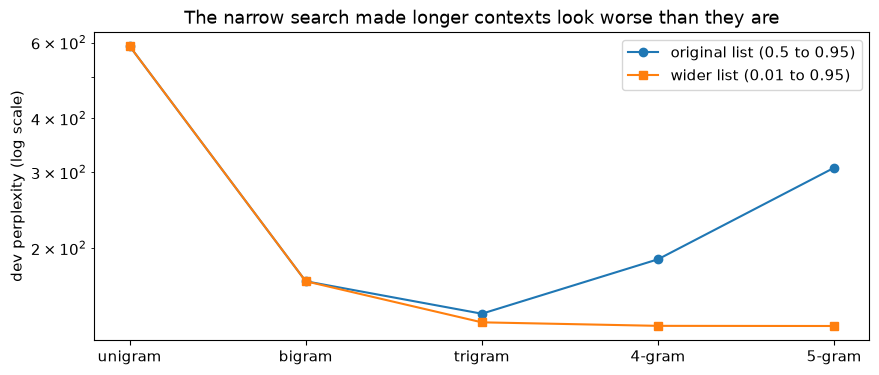

In [18]:
orders = list(ORDER_NAMES)
plt.plot(orders, [dev_perplexity[order] for order in orders], 'o-', label='original list (0.5 to 0.95)')
plt.plot(orders, [wider_dev_perplexity[order] for order in orders], 's-', label='wider list (0.01 to 0.95)')
plt.xticks(orders, [ORDER_NAMES[order] for order in orders])
plt.yscale('log')
plt.ylabel('dev perplexity (log scale)')
plt.title('The narrow search made longer contexts look worse than they are')
plt.legend()
plt.show()

With a suitable weight, the 4-gram and 5-gram are no worse than the trigram: extra context stops helping, rather than hurting. The next step would be to re-tune with the wider list and score the test set once with those settings.

## 8. Final evaluation on the test set

The test set is used here for the first and only time. It is scored with the settings chosen in section 7. Perplexity is only comparable between models that use the same cleaning and vocabulary, which is true for all five here.

In [19]:
test_perplexity = {}
for order in ORDER_NAMES:
    test_perplexity[order] = perplexity(test_sentences, order)
    print(f'{ORDER_NAMES[order]:<8} test perplexity {test_perplexity[order]:7.1f}   (dev {dev_perplexity[order]:.1f})')

best_order = min(test_perplexity, key=test_perplexity.get)
predicted_tokens = sum(len(sentence) - 1 for sentence in test_sentences)
print(f'\nTest tokens predicted: {predicted_tokens:,}')
print(f'The {ORDER_NAMES[best_order]} is {test_perplexity[1] / test_perplexity[best_order]:.1f}x less perplexed than the unigram')

unigram  test perplexity   595.9   (dev 588.9)


bigram   test perplexity   167.3   (dev 167.6)


trigram  test perplexity   139.2   (dev 140.9)


4-gram   test perplexity   184.6   (dev 188.4)


5-gram   test perplexity   299.6   (dev 307.2)

Test tokens predicted: 147,816
The trigram is 4.3x less perplexed than the unigram


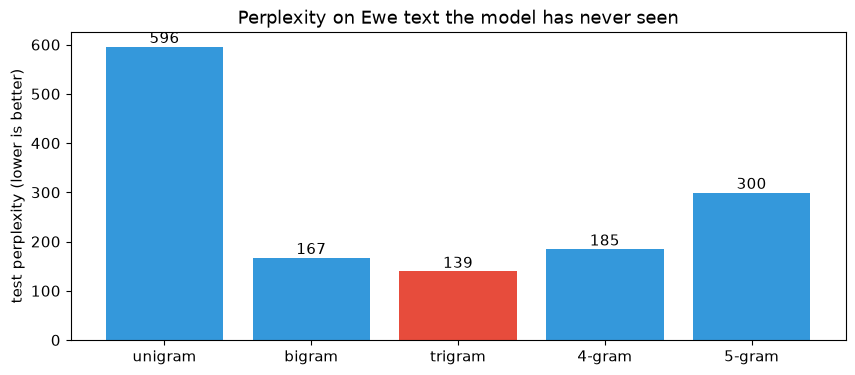

In [20]:
bar_colours = ['#e74c3c' if order == best_order else '#3498db' for order in ORDER_NAMES]
bars = plt.bar([ORDER_NAMES[order] for order in ORDER_NAMES], test_perplexity.values(), color=bar_colours)
plt.bar_label(bars, fmt='%.0f')
plt.ylabel('test perplexity (lower is better)')
plt.title('Perplexity on Ewe text the model has never seen')
plt.show()

## 9. Generating Ewe text

To write a sentence we start at `<s>` and repeatedly:
1. look up which words followed the most recent words in training (using the longest context that was ever seen);
2. keep the 50 most probable of them;
3. pick one at random, weighted by probability;
4. stop at `</s>` or after 12 words.

**Temperature** reshapes the weights: below 1 plays it safe, above 1 takes more risks. We fix the random seed so the samples can be reproduced.

In [21]:
words_that_followed = {}
for n in range(2, HIGHEST_ORDER + 1):
    words_that_followed[n] = defaultdict(list)
    for ngram in ngram_counts[n]:
        context, next_word = ngram[:-1], ngram[-1]
        words_that_followed[n][context].append(next_word)

In [22]:
def candidate_next_words(sentence_so_far, order):
    longest_context = min(order - 1, len(sentence_so_far))
    for context_length in range(longest_context, 0, -1):
        context = tuple(sentence_so_far[-context_length:])
        if context in words_that_followed[context_length + 1]:
            return {word: probability(context, word) for word in words_that_followed[context_length + 1][context]}

    common_words = [word for (word,), _ in ngram_counts[1].most_common(500) if word != START]
    return {word: probability((), word) for word in common_words}


def generate_sentence(order, max_words=12, temperature=1.0, keep_top=50):
    sentence = [START]
    for _ in range(max_words):
        candidates = candidate_next_words(sentence, order)
        top_candidates = sorted(candidates.items(), key=lambda pair: pair[1], reverse=True)[:keep_top]
        words = [word for word, _ in top_candidates]
        weights = [p ** (1 / temperature) for _, p in top_candidates]
        next_word = random.choices(words, weights=weights)[0]
        if next_word == END:
            break
        sentence.append(next_word)
    return ' '.join(sentence[1:])

In [23]:
random.seed(RANDOM_SEED)

for order in ORDER_NAMES:
    print(ORDER_NAMES[order].upper())
    for _ in range(3):
        print('  ', generate_sentence(order))

UNIGRAM
   wo . , , na dzi eƒe . la . , ame
   . , nu aɖe , ƒe ke . hã kple ɖe le
   ɖo
BIGRAM
   ame aɖewo wo ɖe ƒe yehowa le ʋu le ame geɖe wo
   nye
   elabena ame si me .
TRIGRAM
   ame si wɔ nuwo katã le esi wòdi be yealé ame siwo
   eye wotsɔ kplɔ la , mawu nye míaƒe mɔkpɔkpɔ la ƒe nu
   le kwasiɖa , april , dzi kpɔkpɔ ƒe dzodzroa dzi .
4-GRAM
   eya , ame si zu nyagblɔɖila sẽŋu le nya kple nuwɔna me
   ame siwo abɔbɔ wo ɖokui ɖe gbɔdɔdɔ manɔsenu me alo ame makɔmakɔ
   eye fia la kpa konyifaha na abner gblɔ be ðe yehowa ,
5-GRAM
   .
   ɖe ha wo le gea ale be seƒoƒo ƒo xla wo seƒoƒo
   ƒe wuiene sɔŋue nye esia wokpɔ dɔ sia le ŋuwò , ke


In [24]:
for temperature in (0.5, 1.0, 2.0):
    print(f'bigram, temperature {temperature}:', generate_sentence(2, max_words=10, temperature=temperature))

bigram, temperature 0.5: eye ame si me .
bigram, temperature 1.0: ŋutsuvi eve .
bigram, temperature 2.0: le eƒe axa si ƒe ŋkume . me la to


The unigram output is unordered common words, because it picks each word on its own. Higher orders read more fluently, but much of that is repeating phrases from the training text. Whether a sample is grammatical Ewe needs a native speaker to judge.

## 10. Looking inside the model

Which words does the bigram model expect after three common words?

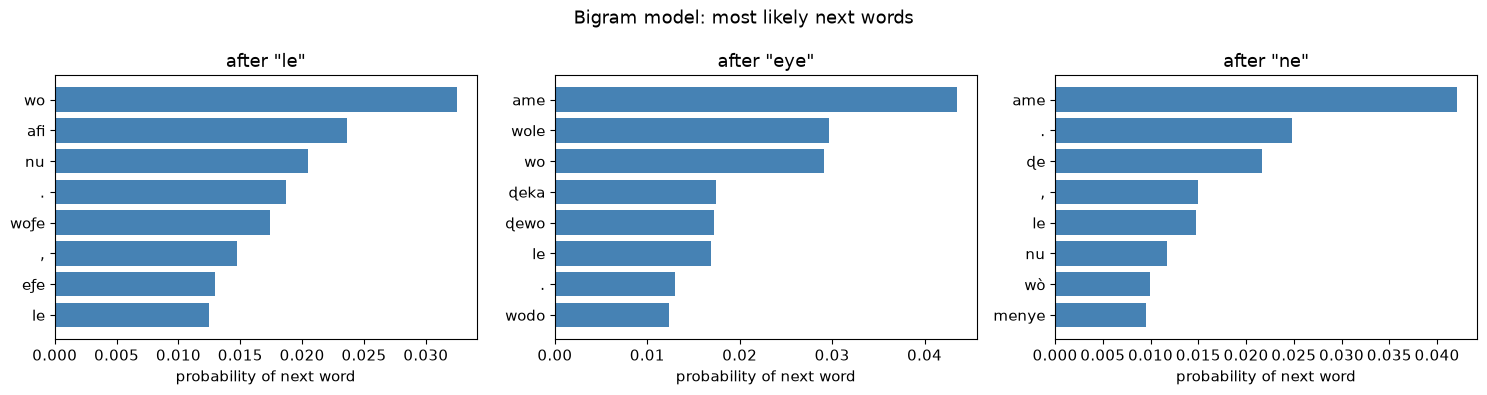

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, word in zip(axes, ['le', 'eye', 'ne']):
    followers = words_that_followed[2][(word,)]
    ranked = sorted(followers, key=lambda follower: probability((word,), follower), reverse=True)[:8]
    ax.barh(ranked[::-1], [probability((word,), follower) for follower in ranked[::-1]], color='steelblue')
    ax.set_title(f'after "{word}"')
    ax.set_xlabel('probability of next word')
plt.suptitle('Bigram model: most likely next words')
plt.tight_layout()
plt.show()

A word-by-word breakdown shows exactly *where* a sentence surprises the model. A very negative number means the model found that word unexpected.

In [26]:
def explain_sentence(text, order=2):
    tokens = clean_and_tokenize(text)
    log_probabilities = word_log_probabilities(tokens, order)
    for position, log_probability in enumerate(log_probabilities, start=1):
        context = ' '.join(tokens[max(0, position - (order - 1)):position])
        flag = '   <-- very surprising' if log_probability < -10 else ''
        print(f'{context:>20} -> {tokens[position]:<10} {log_probability:8.2f}{flag}')
    print(f'sentence perplexity: {math.exp(-sum(log_probabilities) / len(log_probabilities)):.1f}')


explain_sentence('Ame le mia si, ame le mia, enkoe nye yesu kristo')

                 <s> -> ame           -2.98
                 ame -> le            -4.25
                  le -> mia           -5.94
                 mia -> si            -3.30
                  si -> ,             -4.06
                   , -> ame           -3.40
                 ame -> le            -4.25
                  le -> mia           -5.94
                 mia -> ,             -4.35
                   , -> enkoe        -15.43   <-- very surprising
               enkoe -> nye           -6.30
                 nye -> yesu          -5.90
                yesu -> kristo        -2.41
              kristo -> </s>          -4.90
sentence perplexity: 189.1


## Summary

| Step | What we did |
|---|---|
| Data | 47,765 Ewe lines from two sources → 47,131 sentences, about 1.5M tokens; half of all distinct words appear once |
| Cleaning | lowercase, keep Ewe letters and `. , ! ?`, drop digits and other symbols, add `<s>` and `</s>` |
| Model | counts for orders 1 to 5; add-k for single words, interpolation for longer contexts |
| Tuning | grid search on the dev set; the first list of weights was too narrow, and a wider one removes the apparent penalty for longer contexts |
| Evaluation | test perplexity falls about 4× from unigram to trigram, and dev and test agree closely |

**Limits.** We trained no neural model, so we cannot claim n-grams beat neural models in general. The Kaggle half of the corpus is partly religious in register, no native speaker has rated the output, and the cleaning splits off separately stored accents.

**Next steps.** Re-tune with the wider list and score the test set once, try Kneser-Ney smoothing, fix the cleaning, and compare against a neural model.